# Introduction to Python in JupyterLab

Welcome to programming in JupyterLab! JupyterLab is a so-called "interactive development environment," or IDE, which can be used to edit and run programs in a variety of different programming languages, but it was built specifically for Python (hence the weird spelling of JuPYter). A unique feature of Jupyter is the ability to combine your code alongside its output and additional text and figures all in one well-formatted, easy-to-read place. Your project lives in a Jupyter notebook, with the file extension `.ipynb`, but it can also be exported to a number of other formats, such as `.pdf` or `.html`.

Navigating JupyterLab is much like any other computer program, with functions located in the task bar in the top left; most of these tools also have keyboard shortcuts listed next to them so that you can work a bit faster. The panel on the left shows the files and folder you are working in, along with shortcuts to create new files, folders, and upload. The circular icon below the file folder manages all the open projects you have, as well as any kernels you have running. A kernel is essentially where the computer stores short-term data for the project; it starts when you open a project, and clearing the kernel erases any variables you've made in your program. The triple line emblem on the left takes you to an outline of your notebook, and the final tab with the puzzle piece manages extensions which allow you add functionality that isn't native to JupyterLab. 

**Optional:** The following video provides a useful introduction to the JupyterLab environment, including some examples to follow along on your own. The first hour or so has good information for any user, while the remainder covers some extra features which may/may not be of interest. 

Tutorial video: https://www.youtube.com/watch?v=RFabWieskak

## Navigating the Notebook

### Text (Markdown) cells

A Jupyter notebook is essentially comprised of both text cells and code cells; these words live in (you guessed it) a text cell. The text is formatted using a tool called Markdown, which allows you to create section headings like the one above, **bold text**, *italics*, `code text`, and most all the other features of a typical word processor. JupyterLab also knows how to interpret $\LaTeX$, a typesetting program which is widely used in academia for formatting mathematics; this allows a user to create inline equations like $x = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a}$ or larger equations like

$$ \left(-\frac{\hbar^2}{2m} \nabla^2 + V(\vec{r})\right)\Psi(\vec{r},t) = -i\hbar \frac{\partial}{\partial t} \Psi(\vec{r},t). $$

If you want to know how to do any of the things you see typed in one of these text cells, simply double click the cell, which reveals everything behind the scenes. After you're done typing something, press `Ctrl+Enter` to run the cell and render the formatted text.  If you want to know how to do something that you haven't seen before, or don't remember, just go to a new tab and search for "multiline equation latex" or "subsubheading markdown" to learn the formatting. 

If you want to try typing your own text or equations at any point, you can create a cell below the current one by pressing `B` (for below) and then `M` (for Markdown). Then, you can double click into the new cell and type away. 

### Code Cells

The bulk of your programming work is done in code cells, which is the default when a new cell is created. Simply type in the commands you would like to evaluate into the cell, then press `Ctrl+Enter` to run the code (or `Shift+Enter`, which runs the code and progresses to the next cell). The output of the code in that cell will automatically be displayed beneath it, whether that is a print statement, plot, or any warnings or errors created by your code. 

The first code cell you see in almost any project is importing any packages you need to do your work. While Python has many commands built in, the real value of Python is the ease at which other users can develop new functions and share them with others in packages; to access these, you simply need to download and install the package from the internet, then import it in any project which uses them. If you installed Python via the Anaconda distribution, many packages you need are already installed to your computer, you just need to import them. 

The following code cell imports two of the most commonly used packages for scientific work: `numpy` and `matplotlib`. `numpy` includes a wide variety of mathematical functions beyond the inbuilt Python defaults, while `matplotlib` is a library for creating plots (clever name). I've also include calls to the `sys` and `IPython` packages, which can be used to tell you information about the technical specifications of your Python installation. You'll rarely need this information outside of occasional troubleshooting, but it's good to know how to find it. 

In [1]:
# import numpy and matplotlib
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# import packages for Python version information
import sys 
import IPython
print("Python version:", sys.version)
print("IPython version:", IPython.__version__)
print("NumPy version:", np.__version__)

Python version: 3.11.4 (main, Jul  5 2023, 08:54:11) [Clang 14.0.6 ]
IPython version: 8.12.0
NumPy version: 1.24.3


A couple of other details from that cell: 
- After importing `numpy`, I gave the package a shortened name `np`; since I'll usually need to call a lot of functions from `numpy`, this saves me the trouble of writing it out every time. I've done the same for `matplotlib.pyplot`, calling it `plt`; these abbreviations are fairly standard, but you could change them to whatever you'd like. 
- I've also added the line `%matplotlib inline` to ensure that any plots we create will render after they're created; otherwise, the computer makes the plot, but doesn't display it automatically without another command `plt.show()`. 
- The lines before the import commands which start with a `#` are comments; most programming languages use either a `#` or `%` to designate comments, and anything following those characters is ignored when the computer runs the code. Use comments more often that you think you should to describe what is happening in your code, as they help other users understand how the code works - including the most important user: you, at a later time.

## Precision

Computers store numbers in a variety of different ways, and while they may seem equivalent up front, they can dramatically effect the way a computation is done. Often, this only causes problems in certain edge cases, but we need to be aware of some of these details so that we aren't completely lost when a strange error shows up in our code. Consider the following computations, comparing the results of two equations:

In [2]:
print(1 + 2 == 3)
print(0.1 + 0.2 == 0.3)

True
False


Despite both of these equations obviously being true analytically, the computer seems to disagree about the second one. Why did dividing the first equation by 10 ruin our result? The first reason has to do with the type of variables use; more on that in the section on Variable Types. To see the second reason, lets first see what the computer *actually* thinks $0.1+0.2$ is equal to. 

In [3]:
print(0.1 + 0.2)

0.30000000000000004


The computer seems to have found an extra $4\cdot10^{-17}$ in our addition, but where did this come from? Computers store data in binary, or base 2. This is equivalent to counting on our hands if we only had thumbs (0, 1, 10, 11, ...). Because of this, numbers that seems to be simple, finite decimals like 0.1 actually have more complicated, non-terminating decimal forms in binary. However, our computer only has a finite amount of memory to store the data, so it has to cut off digits somewhere. This loss of precision leads to inaccuracies like what we see here. Does this actually matter though? Despite being a seemingly insignificant difference, this can create a lot of headaches, especially when the values are stored in variables, and therefore may not always be known to the user. Consider the following example:

In [4]:
a = 0.1; b = 0.2;
x = a + b;

print(np.sqrt(0.3 - x))

nan


/var/folders/qd/vhrm224n76l0sb7xy_mg2g300000gn/T/ipykernel_4681/2195892426.py:4: RuntimeWarning: invalid value encountered in sqrt
  print(np.sqrt(0.3 - x))


Because of the precision issue, my calculation above has returned `nan`, which stands for "not a number." My code has "unknowingly" asked the computer to take the square root of a negative number, causing the computer to throw the warning above.

This discussion may also lead to the question: if the computer can only store finitely many digits, what is the smallest precision one can compute on a computer? The smallest difference between two numbers that a computer can calculate is called machine epsilon $\epsilon$. If two numbers $x$ and $y$ are closer than this number, the computer considers them equivalent; written out in math:

$$ |x-y|<\epsilon \Rightarrow x\equiv y $$

in the eyes of the computer. For your computer, you can find this smallest difference by running the code below:

In [5]:
fi = np.finfo(float);
print(fi.eps)

2.220446049250313e-16


You should find this number is on the order of $\sim 10^{-16}$, meaning that your computer generally has about 16 decimal digits of precision. The actual smallest or largest number that your computer can store will depend on what variable type you are trying to store.

## Variable Types

### Integers

In the example above, our first equation used integers for the calculation, which the computer uses the variable type `int` to store. Most programming languages will offer at least two different types of integer, including `int32` or `int64`, with the number specifying the number of bits of computer memory used to store the value. Integers are useful for a variety of different applications, but have slightly different rules for certain mathematical operations (more on this with the calculator section).

You can see the largest and smallest integers your computer can use below:

In [6]:
ni = np.iinfo(int);
print(ni.max)
print(ni.min)

9223372036854775807
-9223372036854775808


### Floating Point Numbers

The decimals in the second equation are floating point numbers, called a `float`, which again may have different types depending on the number of bits. Generally, floating point numbers are stored with 1 bit to store the sign ($\pm$), some number of bits to store the **exponent** $x$, and the remaining bits for the **mantissa** $M$; these numbers are combined to express whatever number in a form much like scientific notation, so that an arbitrary number $a$ is expressed as 

$$ a = \pm M \cdot 2^x $$

As we saw above, floating point arithmetic doesn't work exactly as we expect from our knowledge of pen-and-paper mathematics, but it is the language with which computers do math. If you want more nitty gritty detail on how this works, you can read all about the technical side of things on [Wikipedia](https://en.wikipedia.org/wiki/IEEE_754) or by searching elsewhere for IEEE 754.

The largest, smallest, and largest negative floats your computer can work with are shown below:

In [7]:
print(fi.max)
print(fi.min)
print(fi.tiny)

1.7976931348623157e+308
-1.7976931348623157e+308
2.2250738585072014e-308


### Boolean

One other variable type that often shows up in program is a Boolean, or `bool`. This is a logical variable, meaning that it can only be 1 or 0, `True` or `False`. The entire statement `1+2 == 3` seen above is a Boolean with the value `True`; Booleans can also be made with other more logical comparisons like `==`, `<`, `>`, `<=`, `>=` and by combining logic statements with Boolean operators `and`, `or`, `xor`, or other more complicated logical operators. We can use Booleans in loops to define how many times to do a calculation.

### Characters and Strings

The last variable types are characters and strings (`char` and `str`); in Python, these variables are always written inside of single or double quotations and will often be used in print statements or to create labels of plots. Characters and strings can also be used in "arithmetic" statements, but have two different versions of these computations - one which just uses the numerical value assigned to the letters (remember, the computer stores everything as a binary number), and another which manipulates the actual letters (such as concatenating strings together). 

## Python as a Calculator

The primary function of a computer is to do arithmetic operations (and logical operations, which are just binary arithmetic); as such, every programming tutorial starts with having you use the language for its most fundamental (and frankly, boring) function: as a calculator. In Python, all the usual arithmetic operations are built in as you might expect: `+ - * /` to perform arithmetic on numbers. One unusual operator is exponentiation; you might expect to type `x^y` to raise $x$ to the power $y$, but `^` is reserved for the binary operator XOR; instead exponentiation is expressed as repeated multiplication: `x**y`. 

### Division: the Problem Child
There are technically 3 different division operators in Python:
 - Float division `/`: the "normal" one
 - Integer division `//`
 - Modulo (or remainder) `%`

Regular float division works the way you probably would expect, returning a float (or decimal) for whatever quotient you want to calculate. Integer division essentially "rounds down" every answer, truncating the decimal part of the quotient and leaving you an integer answer (though not necessarily an `int` variable type). Finally, the modulo, or remainder, operator returns the remainder of any division. Because of this, I can get three different answers depending on which division I do:

In [8]:
print(5/3)
print(5//3)
print(5%3)

1.6666666666666667
1
2


## Variable Assignment and Naming

Unlike a usual calculator, most computations in Python will not be done with explicit numbers; rather, you will have numerical values stored in variables. Assigning a variable a value is done simply with the assignment operator `=` (which is different from the logical comparison `==`). Any number you plan to utilize more than once in your code, you should assign a variable with a descriptive name; this way, if you ever want to change the value, you only have to change it where it is defined, rather than tracking down every time you used it. Variable names in Python can use any alphabetical character (upper or lowercase, case sensitive), numerical character, or the underscore `_`; they also cannot begin with a number. The rules for naming variables are slightly different in each programming language; for example, the Julia language allows the user to use any Unicode character, meaning you can name your angle variable $\theta$ if you'd like.

### Practice Problem: 

Create a code cell below this one (by pressing `B`) and create some variables with different values. Then, do some computations and print their results. As an optional challenge, also include a Markdown cell, and try writing out the expressions with your variables in $\LaTeX$.


In [9]:
a = 4;
b = 5;
c = 8;

print(a+b*c)
print((a-1)/c)

44
0.375


$$ a+bc = 44;\ \frac{a-1}{c} = \frac{3}{8} = 0.375 $$

## NumPy Arrays

Very often we will need to store many pieces of data within the same variable, and there are two common ways to do this. Python's default entity is called a list, which is contained in square brackets `[]`, with each item separated by commas `,`. It can contain any data types; for example, I can create 

In [10]:
mylist = ['a', 'string', 4, 5.6];

which contains a character, a string, an integer, and a float. Instead, we often prefer to use NumPy arrays to store lots of values, which have the restriction that each value must have the same type in order to do operations with them. I can then perform two different types of operations. **Scalar** operations will apply the same operation to every value in an array, such as adding 5 to every element. **Elementwise** operations must be done between two arrays with the same dimension, and the operators are applied between elements in the same position in the array. For example: 

In [11]:
x = np.array([[1,2],[3,4]])

# Scalar:
print(10+x)

# Elementwise
print(x*x)

[[11 12]
 [13 14]]
[[ 1  4]
 [ 9 16]]


### Creating Arrays

Probably the most commonly used functions for making arrays are listed below:

 - `np.array()`: converts an input Python list into a NumPy array, as seen above in the example for `x`.
 - `np.linspace(start, stop, n)`: creates an array which has the starting value `start` and contains a total of `n` evenly spaced elements in the array, up the ending value `stop`.
 - `np.arange(start, stop, dx)`: creates an array which has the starting value `start` with a spacing of `dx` between each value up to the ending value `stop`.
 - `np.zeros(n)`: creates an array with `n` zeros. You can also enter a list of sizes to create higher dimensional arrays; see the documentation for more details.
 - `np.ones(n)`: same as `np.zeros`, but fills the array with ones.
 - `range(start, stop, step)`: creates a sequence of numbers from `start` to `stop` with an interval `step` between. This is often used in `for` loops and will usually just be written as `range(stop)`, with the default starting from 0 and a step of 1. This is technically not an array, but its own special type.
 
We use `np.linspace` when we want to compute a fixed number of values across an interval, or `np.arange` when we want a fixed spacing across an interval. By default, `np.linspace`, `np.arange`, and `range` do not include the `stop` value, but there is an optional argument to include it; see the documentation for more details. `np.zeros` and `np.ones` are useful for initializing an array before some operation (more on that with loops). 

### Array Indexing

Another important feature of arrays (and lists) is indexing, which allows you find individual values, or a subset of values from an array. For example, if I just want the third entry in `mylist` from above:

In [12]:
print(mylist[3])

5.6


Hold on, that's the fourth entry; I clearly asked for 3. Python indexes starting from 0, so the first entry is at position `0`, second at position `1`, and $n^{th}$ at position `n-1`. I can also get the item in row 1, column 2 of my array `x` by doing

In [13]:
print(x[0,1])

2


Again, notice the off-by-1 issue here. This WILL be a source of confusion in many scenarios, especially since just as many languages (Matlab, Mathematica, Julia, R, and more) start indexing at 1 as those that start at 0 (Java, C, C++, Python, etc.). 

Another very useful tool is **logical indexing**, which allows you to find where values are that meet a certain criterion. Suppose I want to know which values my array `x` are less than 3; then I can type:

In [14]:
print(x[x<3])

[1 2]


You could read this statment as "Print the elements of `x` where the values are less than 3." This can be particular helpful if I want to find a value in array which corresponds to a value in another array; for example, suppose I want to find the position of an free falling object at t=4 seconds, from an array of values:

In [15]:
x0 = 100;   # initial position
v0 = 3;     # initial speed
g = -9.8;   # accel due to gravity

time_arr = np.linspace(1,10,10);
position_arr = x0 + v0*time_arr + 0.5*g*time_arr**2;

print(position_arr[time_arr==4])

[33.6]


The last line here prints the `position_arr` value at the same position where the `time_arr` is equal to 4.

### Practice Problem:

Create an array of 21 evenly-spaced time values between 0 and 5 seconds. At each time step, compute the speed of an object with mass $m=5$ kg in free fall ($g=9.8$ m/s/s) starting from rest, and the kinetic energy. What is the kinetic energy when $t=3.5$ seconds? Make sure to give all your variables intuitive, descriptive names.

In [16]:
## define constants
m = 5
g = 9.8
tarr = np.linspace(0,5,21);

varr = 0.5*g*tarr**2;
KEarr = 0.5*m*varr**2;

print("KE(t=3.5) = ",KEarr[tarr==3.5])

KE(t=3.5) =  [9007.5015625]


## Functions

Functions in programming are essentially the same objects as functions in mathematics: they take some set of inputs (sometimes called arguments), perform some calculation or process on the inputs, and return some type of output. Many inbuilt Python functions also include optional arguments which slightly alter the functionality. In order to know the proper inputs, possible options, and how the function formats outputs, you can always refer to the documentation. This can almost always be found by searching online for the function name, followed by "python" or maybe the package name. You can also find the documentation for functions within JupyterLab by typing `?function_name` in a code cell. For example, if I want to know all the gory details about the function for cosine in `numpy`, I can type:

In [17]:
?np.cos

Call signature:  np.cos(*args, **kwargs)
Type:            ufunc
String form:     <ufunc 'cos'>
File:            ~/anaconda3/lib/python3.11/site-packages/numpy/__init__.py
Docstring:      
cos(x, /, out=None, *, where=True, casting='same_kind', order='K', dtype=None, subok=True[, signature, extobj])

Cosine element-wise.

Parameters
----------
x : array_like
    Input array in radians.
out : ndarray, None, or tuple of ndarray and None, optional
    A location into which the result is stored. If provided, it must have
    a shape that the inputs broadcast to. If not provided or None,
    a freshly-allocated array is returned. A tuple (possible only as a
    keyword argument) must have length equal to the number of outputs.
where : array_like, optional
    This condition is broadcast over the input. At locations where the
    condition is True, the `out` array will be set to the ufunc result.
    Elsewhere, the `out` array will retain its original value.
    Note that if an uninitialized 

which is far more information then you will ever need to know about the inbuilt cosine function. This feature becomes more valuable as you get into packages with more complicated functions, such as the `scipy.linalg` package we will use later, which has functions for working with matrices; the functions we'll need may have many optional arguments to help optimize the function for our specific applications. 

**Warning:** While most of the major libraries like `numpy`, `scipy`, and `matplotlib` have extensive documentation, smaller packages made by other users that are available online may have little to no documentation. There really is no standard way to document functions, so in some of those cases, functions may not work the way you think they should, and you may just be better off writing your own function instead of figuring out whatever the hell this stranger online has created. 

One of the most important skills in programming is defining your own functions; while there are many functions built for you native to Python or in packages, it's up to you to utilize those to define new functions which perform the specific tasks in your project. They also help to simplify and organize a program; as a rule of thumb, any section of code which you are going to use more than once in a program, you *could* just copy and paste the code, but you *should* write a function for it.

An example of a function is shown below.

In [18]:
def flight_time(v, theta=45.):
    '''
    Determines the time of flight for a projectile
    launched with speed v at an angle theta (in degrees)
    over flat ground.
    '''
    g = -9.8;
    theta_rad = np.deg2rad(theta);
    vy = v*np.sin(theta_rad);
    t = -2*vy/g;
    
    return t

v = 20;
theta = 30;
print(flight_time(v))
print(flight_time(v,theta))

2.8861501272920305
2.040816326530612


Let's dissect every piece of this to understand what all is happening here:

 - To begin defining the function, you start with the text `def`. Immediately after is the name of my function `flight_time`, followed by its arguments `v` and `theta` in parentheses. This line ends with a colon, meaning that the body of the function follows in the next few lines.
 - `theta` has a default value of 45; this means that if the user doesn't specify an angle, the computer just assumes 45 and does the calculation with this value.
 - After the function definition is the documentation string, or doc string. This is wrapped in triple quotes and serves as the documentation for your function, which you can view in the same way as any other inbuilt function. You should try to be more detailed than I have been here, so that your code is readable and understandable to as many people as possible.
 - The next few lines is the action of the function: I define a value for the acceleration due to gravity `g`, convert my angle to radians using the inbuilt `numpy` function `numpy.deg2rad`, and then compute the $y$-component of velocity and time of flight.
 - Lastly, I use a `return` statement to tell the function to use the value of `t` as the result.
 - Your function doesn't have to end in a `return` statement; it could have a `print` statement as the result, or create a plot, or just stop with no output. Python distinguishes the body of the function from the rest of your code by the indentation; so that any code that follows the body of the function and isn't indented, isn't part of the function. This is fairly unique to Python; other languages will often require an `end` or other keyword to indicate that the function is complete.

A good function will also have a descriptive name which tells you roughly what it does. A useful trick as you are working in JupyterLab or most other IDEs is tab completion; if you don't know the full name of a function, or just don't want to type it out, you can type the first few letters, then press `Tab`, and the IDE will fill in the rest of the name or offer a drop-down menu of possible functions which start with those letters. 

### Practice Problem:

Create a code cell below this one and try writing your own functions for a new scenario: consider launching a projectile horizontally from some height $h$ at a speed $v$. Write a function for the time the projectile spends in the air, then a new function which computes the horizontal distance the projectile will travel. You should also test your function by evaluating it with a few different values, including some easy cases that you already know the answer, in order to make sure it works. 

In [19]:
def time(h):
    '''
    Computes the time a projectile will spend in the air 
    when launched horizontally from height h at speed v;
    flight time doesn't depend on v since vy = 0 for 
    horizontal launch.
    '''
    g = 9.8;
    t = np.sqrt(2*h/g)
    return t

def distance(h,v):
    '''
    Computes the horizontal range of a projectile launched
    horizontally from a heigh h at speed v.
    '''
    x = v*time(h)
    return x

## Conditionals

Conditional statements are used to tell your program that a certain piece of code should only be run if some condition is met. There are three basic conditional statements you will need: `if`, `elif`, and `else`, in conjunction with the logical comparisons (such as `==`, `<`, `>`, etc.) and logical operators (`and`, `or`, `xor`, `not`, etc.). The basic of structure is that `if` something is true, execute some code; `else`, execute a different piece of code. If you want to test for multiple conditions, `elif` is short for else-if and can be used to check a new condition after the first.  The syntax is very similar to the function syntax, so let's see an example to get an idea of how this works.

In [20]:
age = 22;

if age<13:
    print("You are a child.")
elif age>=13 and age<=18:
    print("You are a teenager.")
else:
    print("You are an adult.")

You are an adult.


The first condition to check is that the variable `age` is less than 13, so we write `if age<13` followed by a colon; like functions, the code to execute if the condition is met is written in the lines beneath the conditional statement and indented; any code not indented will be considered outside of the conditional. The following lines create conditions for if `age` is between 13 and 18, and above 18. Try changing the value of `age` to see how the results change.

### Practice Problem:
If you enter a negative number for `age` above, it should tell you that you're an child, but negative age doesn't make a whole lot of sense does it? Modify the code above so that it prints an error message if you enter a negative number. 

In [21]:
age = -22;

if age<0:
    print("ERROR: Please enter a nonnegative value.");
elif 0<=age<13:
    print("You are a child.")
elif age>=13 and age<=18:
    print("You are a teenager.")
else:
    print("You are an adult.")

ERROR: Please enter a nonnegative value.


## Loops

Loops are used to run the same piece of code many times repeatedly; there are two basic kinds of loops you may need. The `for` loop is used primarily when you have a fixed number of iterations of your code; for example, you may want to use each value from an array once, so you would create a variable sometimes called an **iterator**, which takes on each value of the array for each time through the loop. Here's an example of 1D motion with constant acceleration:

In [22]:
a0 = 2; 
v0 = 0; 
x0 = 0;

npts = 5;

velocity_arr = np.zeros(npts);
position_arr = np.zeros(npts);

for t in range(npts):
    velocity_arr[t] = a0*t;
    position_arr[t] = v0*t+0.5*a0*t**2;

Here's a breakdown of what all is going on here:
 - Before the loop, I've defined all of my initial parameters: the constant acceleration `a0`, my initial speed `v0`, and my initial position `x0`. I've also defined that I want to do my calculation `npts` number of times.
 - I've created two arrays of zeros, each with `npts` elements. This is where I'm going to store the result of each calculation. This is called **initializing** the array; you can technically get away without doing it, and each time through the loop, the computer will just add the new result on to the end of the array, but its faster for your computer to just create the whole array at once beforehand, and then replace the values at each step of the loop.
 - The loop begins by defining by iterator `t` and saying that it will take on each value in the `range(npts)`, which means that `t` will take on the values 0, 1, 2, 3, and 4 on each successive iteration of the loop.
 - The usual format of a colon after the `for` statement and then an indented body of the loop; within this body, I am computing the velocity and position at time `t` and storing it in the array I initialized for each quantity at the `t`<sup>th</sup> position. 

The other kind of loop you may use is a `while` loop, which is useful when you aren't sure how many iterations of the loop you may need. Instead, the loop will run for as long as some condition is `True`. A word of caution: you can often easily and accidentally make infinite loops, if you don't include code to update your condition. If you start a while loop and it seems like your computer is going nowhere, interrupt the program by pressing `I` twice in JupyterLab (or `Ctrl+C` in many other settings), and double check your code to make sure it's not going to run forever with no chance of stopping. Let's look at another example:

In [23]:
a0 = 2; 
v0 = 0; 
x0 = 0;

npts = 5;

velocity_arr = np.zeros(npts);
position_arr = np.zeros(npts);

j = 0;
while j<npts:
    velocity_arr[j] = a0*j;
    position_arr[j] = v0*j+0.5*a0*j**2;
    j+=1;

The opening lines of this are copied and pasted from before; the new stuff is as follows:
 - My new iterator variable `j` is initialized to a value of 0. I open the loop with the condition that the loop should run for as long as the value of `j` is less than the value of `npts`.
 - Each time through the loop, I compute a velocity and position and assign it to the `j`<sup>th</sup> position of the respective array.
 - The last line saves my computer from having to work for eternity; at each iteration of the loop, I add 1 to the value of `j`; on the iteration when `j==4`, the last line sets `j=5`, and the loop breaks, since the conditional statement is no longer true.

### Practice Problem: 

Using your functions from above for the horizontal projectile, write a program which computes the horizontal distance for 50 evenly spaced values of the height between 0 and 20 meters, for a fixed speed $v=20$ m/s. Also write a program that computes the distance for 50 evenly spaced values of the velocity between 0 and 40 m/s, for a fixed height $h=10$ meters. Make sure to create arrays for all the input height and speed values, as well as the output values, and give these arrays descriptive names; we'll use them later on to make some plots.

In [24]:
npts = 50;
hmin = 0; hmax = 20;
harr = np.linspace(hmin,hmax,npts);
v = 20;

darr1 = np.zeros(npts);
for j in range(npts):
    darr1[j] = distance(harr[j],v);
    
vmin = 0; vmax = 40;
varr = np.linspace(vmin,vmax,npts);
h = 10;

darr2 = np.zeros(npts);
for k in range(npts):
    darr2[k] = distance(h,varr[k]);

## Plotting

For the last portion of this tutorial, we'll cover how to take the results you've calculated and turn them into something presentable. Plotting is one of the most important skills as a physicist, because they take otherwise unintelligible data and convert them into a form that one can easily interpret. Unfortunately, there are an abundance of bad plots all over scientific literature (and elsewhere) which are confusing and/or misleading for providing not enough information, too much information, poor organization, poor labeling, improper axes, etc.; your goal should be **not** to contribute to the plethora of bad, untractable information, and instead create effective, concise visualizations of your data. Luckily, `matplotlib` provides all the tools for this and more, and almost every aspect of your plots can be customized. I'll create a plot with my data from the `while` loop section above, and then go over what each line does.

In [25]:
import matplotlib as mpl
mpl.rc('xtick', direction='in', top=True)
mpl.rc('ytick', direction='in', right=True)
mpl.rc('xtick.minor', visible=True)
mpl.rc('ytick.minor', visible=True)

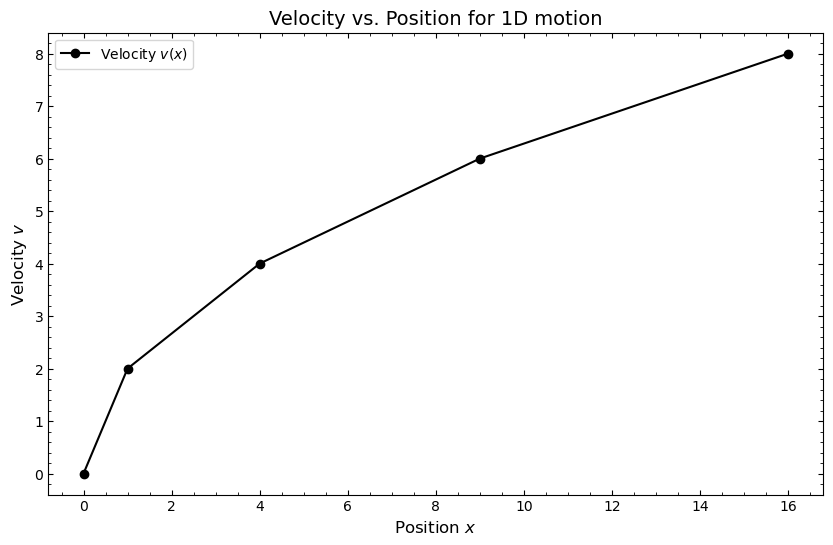

In [26]:
figure1 = plt.figure(figsize = (10,6));
ax1 = figure1.add_subplot(111);
ax1.plot(position_arr, velocity_arr, '-ok', label="Velocity $v(x)$");
ax1.set_xlabel("Position $x$", fontsize=12);
ax1.set_ylabel("Velocity $v$", fontsize=12);
ax1.set_title("Velocity vs. Position for 1D motion", fontsize=14);
ax1.legend(loc='best');

The first cell here are some more optional boilerplate text that would normally live up with `import numpy as np` and your other code that starts the whole notebook. These lines change a few of the default plot settings so that there are major and minor tick marks along all four sides of the graph, pointed inward. This is a personal preference that I think it makes it easiest to read off data points this way, but you may prefer not to use this in your own work. As for the actual plotting commands in the following cell:
 - The 1<sup>st</sup> line creates a figure, called `figure1`, and sets the size to be 10x6 (I'm not actually sure what units this is in, but you can mess with different sizes/aspect ratios). This figure isn't the plot, but rather sets aside space in your computer's memory to create a plot within the figure.
 - The 2<sup>nd</sup> line creates a set of axes and calls them `ax1`. The labeling `111` in the `add_subplot` command tells the computer that `figure1` contains a 1x1 grid of plots, with `ax1` in the first position. If you wanted to make many plots in the same figure, you could, for example, make a 2x2 grid and make `ax3` live in the third (bottom left) position with the labeling `223`.
 - The 3<sup>rd</sup> line is the real action; this plots my independent ($x$) variable `position_arr` and dependent ($y$) variable `velocity_arr` on the axes `ax1`. The option `'-ob'` is shorthand for the options `linestyle='-', markerstyle='o', color='b'` which makes a connected line between the points, a circular marker at each point, and makes the line blue. You can see more details of these options in the documentation for `plt.plot`. The last command creates a label for my plot which will be used in the legend.
 - Lines 4, 5, and 6 create axes labels and a title for my plot and set their fontsize; notice that the labels must be strings enclosed in quotes `""`, and can include $\LaTeX$ formatted equations in the string.
 - The 7<sup>th</sup> and last line creates a legend, and uses the option `loc='best'` to set the location to whatever `matplotlib` thinks is best; you can also control this yourself with options like `upper right', 'lower center`, and similar.
 
As I mentioned earlier, you can customize your plots in just about any way imaginable; if there's anything you want to do (change a color, add a line, add text, have two $y$-axes,etc.), your best option is to search online or in the documentation.

### Practice Problem:

Create plots of horizontal distance vs. height and horizontal distance vs. speed, using the data computed above. Make sure to give your plots axes labels, titles, and legends. 

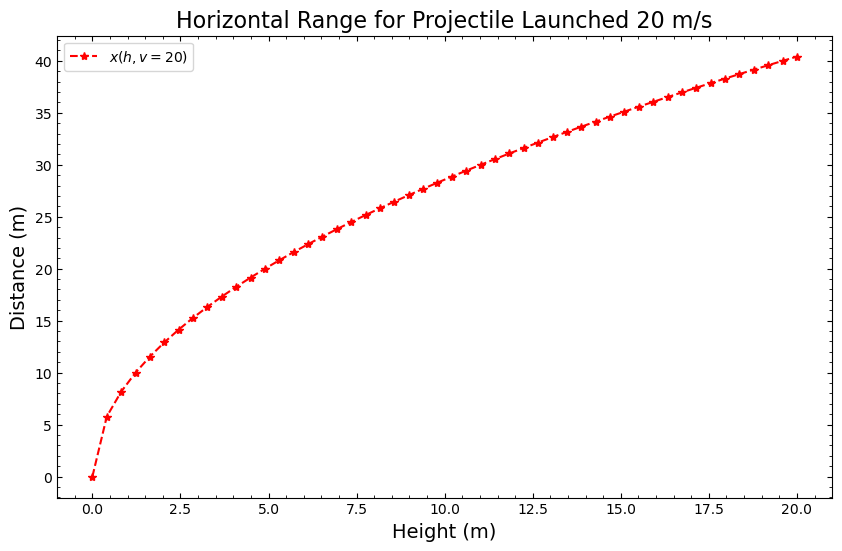

In [27]:
figure2 = plt.figure(figsize=(10,6));
ax2 = figure2.add_subplot(111);
ax2.plot(harr,darr1,'--*r',label="$x(h,v=20)$");
ax2.set_xlabel("Height (m)",fontsize=14);
ax2.set_ylabel("Distance (m)",fontsize=14);
ax2.set_title(f"Horizontal Range for Projectile Launched {v} m/s",fontsize=16);
ax2.legend(loc='best');

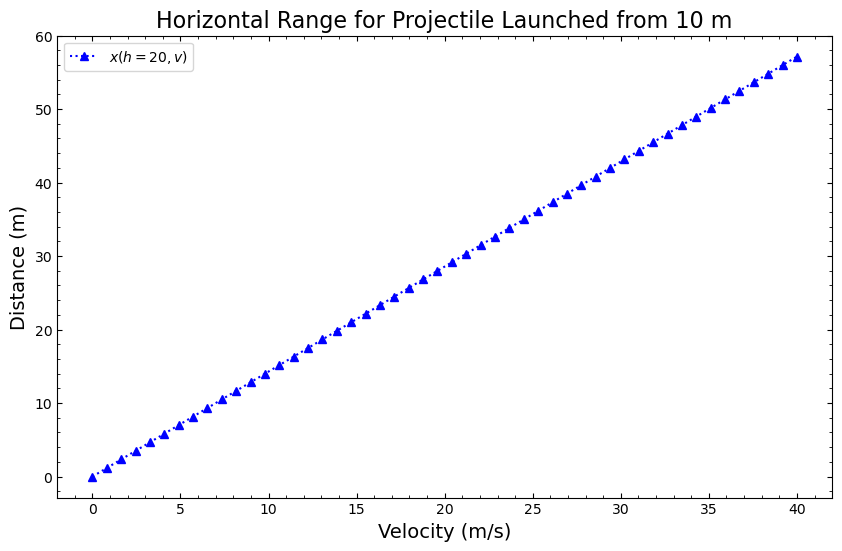

In [28]:
figure3 = plt.figure(figsize=(10,6));
ax3 = figure3.add_subplot(111);
ax3.plot(varr,darr2,':^b',label="$x(h=20,v)$");
ax3.set_xlabel("Velocity (m/s)",fontsize=14);
ax3.set_ylabel("Distance (m)",fontsize=14);
ax3.set_title(f"Horizontal Range for Projectile Launched from {h} m",fontsize=16);
ax3.legend(loc='best');

## Wrap-Up

After working through all of this, you've now been exposed most of the computational tools that you need to tackle a wide variety of problems, and we can start doing some real calculations. I don't expect that you will fully understand all the information presented, nor do I expect that you'll remember it all off the top of your head tomorrow, but the most important thing is that whenever your stuck, you don't need to know the answer; you just need to know how to search for it. The most important resource you have with any programming is other code - either looking back at your own work, or finding the work of others online.  Some important websites to look for are StackExchange (for a forum of programming Q+A), Github (for repositories of other people's code), or simply the documentation for Python, Markdown, $\LaTeX$, or whatever other language you may be using. With the information here and the power of the internet, you're as official a computer programmer as 95% of physicists, who are often the butt of many computer scientists' jokes. However, you know enough to utilize your computer to solve problems, and you don't need to know how to make a hammer to know how to use it. 

## Acknowledgements

Huge thanks to Dr. Craig Copi at the Case Western Reserve University Dept. of Physics, from whom I have learned much of my own programming practices; much of this document is inspired by materials used in his PHYS 250 class.